In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from dotenv import load_dotenv
from langchain_cohere import ChatCohere
from langchain.messages import RemoveMessage

In [2]:
load_dotenv()

True

In [3]:
model = ChatCohere(model="command-a-03-2025")

In [ ]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {} 

In [5]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [6]:
builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")   # run deletion after each response
builder.add_edge("cleanup", "__end__")

In [7]:
graph = builder.compile(checkpointer=InMemorySaver())

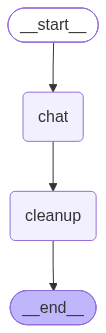

In [8]:
graph

In [9]:
config = {"configurable": {"thread_id": "t1"}}

In [10]:
# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Nitish"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='053694b1-a70c-4dfe-bf33-75b9a81bf7cf'),
  AIMessage(content='**LangChain** is an open-source framework designed to build applications powered by **large language models (LLMs)**. It provides tools and abstractions to create complex, stateful, and context-aware applications that go beyond simple text generation. LangChain is particularly useful for developers and data scientists who want to leverage LLMs for tasks like chatbots, document analysis, question answering, and more.\n\nHere’s a detailed breakdown of LangChain:\n\n---\n\n### **Core Components of LangChain**\nLangChain is built around several key components that work together to create powerful LLM-driven applications:\n\n1. **Models**:\n   - LangChain supports integration with various LLMs, including OpenAI (GPT-4, GPT-3.5), Anthropic, Hugging Face, and more.\n   - It provides a standardized interface to interact with these 

In [11]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
